In [ ]:
HEIGHT = 120
WIDTH = 120
FRAMES = 10
FPS = 1

In [1]:
from query_generator import generate_queries
generate_queries(HEIGHT, WIDTH, FRAMES, FPS)

Done!                                                  


In [ ]:
import subprocess
subprocess.call("align.sh")

In [ ]:
from output_parser import parse_to_json_files
parse_to_json_files()

In [3]:
import json

data = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        with open(f"outputs/fasta_{y:02d}_{x:02d}.json", "r") as f:
            data[(x, y)] = json.loads(f.read())

# data = {}
# for x in range(WIDTH):
#     for y in range(HEIGHT):
#         with open(f"queries/query_{y:02d}_{x:02d}.fa", "r") as f:
#             data[(x, y)] = {
#                 "name": "Test",
#                 "status": "Sequence found",
#                 "sequence": f.read().split('\n')[1]
#             }

print(len(data), "files loaded")

972 files loaded


In [4]:
def get_sequence(coord):
    if coord["status"] != "Sequence found":
        return ""
    s = coord["sequence"]
    if coord["rev-comp"]:
        return s[::-1].replace("A", "_").replace("T", "A").replace("_", "T").replace("C", "_").replace("G", "C").replace("_", "G")
    return s

sequences = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        sequences[(x, y)] = get_sequence(data[(x, y)])

print(sequences[(0, 0)])

CGTTGCACTCCAGCCTGGGCAATAAGAGCAAAACTCCACCTCAAAAAAAAAAAAAAAAAAAAAGAAAGAAAGAAGAAAAAAAAAAGAAACCTCAGAAATCTTCCTGGTGTTTTATTTTACTGTGGCTGAGCTGGTACTCAAACCATGAAGCGTGGTCTTTCCCAGTCCTTCCTCCCCTTTCCACAGGCAGAGGAGCCTCACGCATTGGCCACCACCACTA


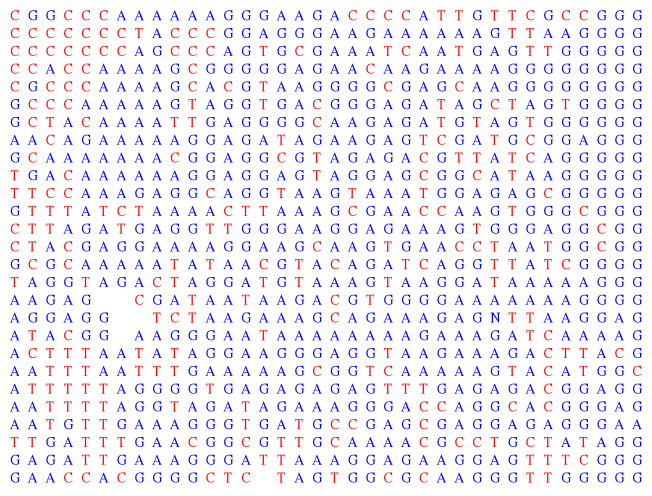

In [53]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation

plt.rcParams['font.family'] = 'STIXGeneral'

fig, ax = plt.subplots()
ax.axis("off")

text_ui = {}
for x in range(WIDTH):
    for y in range(HEIGHT):
        text_ui[(x, y)] = fig.text(x/WIDTH, 1-y/HEIGHT, "", color=color)
    
def draw(i):
    for x in range(WIDTH):
        for y in range(HEIGHT):
            sequence = sequences[(x, y)]
            if sequence != "":
                base = sequence[i]
                color = (1,0,0) if base in "CT" else (0,0,1)
                text_ui[(x, y)].set_text(base)
                text_ui[(x, y)].set_color(color)

ani = animation.FuncAnimation(fig=fig, func=draw, frames=int(FRAMES*FPS/24), interval=1)

FFwriter = animation.FFMpegWriter(fps=FPS*10)
ani.save('animation.mp4', writer=FFwriter)

In [54]:
from IPython.display import Video
Video("animation.mp4")